# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Tangaran, Grisby Paul James
- _Student No._: 2024-02777
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figures

![Error convergence of the integration methods](11-errors.png)

**Figure 1. Error convergence of the integration methods.** Log-log plots of the absolute error of the trapezoid, Simpson 1/3, Simpson 3/8, and Monte Carlo methods, relative to scipy quad, versus the number of points for (left to right) y = √(9 − 4x²) on [0, 3/2], y = −x² + 1 on [−2, 2], and y = √x cos x on [0, π]

![Monte Carlo sampling of the test functions](11-mcs.png)

**Figure 2. Monte Carlo sampling of the test functions.** 5000 random points between each curve and the x-axis for (left to right) y = √(9 − 4x²), y = −x² + 1, and y = √x cos x, with blue points above the x-axis and red points below it

### Report discussion
Figure 1 shows how each method's error decreases as more points are used. For the parabola, **both Simpson rules are exact**, since they integrate polynomials up to degree three without error, while the **trapezoid error falls steadily**. For the two square-root functions, **all Newton-Cotes rules converge more slowly** because **the derivative of the square root diverges at one endpoint**, breaking the smoothness the error terms assume. **Monte Carlo error is noisy and decreases the slowest**, staying well above the Newton-Cotes rules even at the largest n.

Figure 2 shows the Monte Carlo points between each curve and the x-axis. The first function is non-negative, so all its points are blue, while the other two have red regions where they dip below the axis. **Blue points count as positive area and red points as negative**, so **blue minus red gives the signed integral** and **blue plus red gives the total area**. With only 5000 points, the **estimates agree with scipy within a few percent**.

Monte Carlo can arrive at an integral value because, by the **mean value theorem**, an integral equals the interval width times the function's average value. Averaging the function at uniformly random points gives an unbiased estimate of this average, which converges to the true value with error shrinking as 1/√N.

**Newton-Cotes methods are more suitable for smooth integrands in low dimensions**, where their errors shrink much faster and the results are deterministic, as Figure 1 shows. **Monte Carlo is better in high dimensions**, where grids need exponentially more points, and for irregular regions or rough integrands.
### Other comments
- none

---
## Section 2: Code

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.integrate import quad

## Problem: 

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo) 

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)


Output: 
1. total area bounded by the curve, x-axis, and x bounds 
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand

Test your functions on the following curves and bounds:

1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$
2. $$ y = -x^2 + 1, x=-2, x=2 $$
3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

Check your answers (of the integral) with `scipy.integrate.quad`

**Report Figures** (since there are three functions, there should be a total of 6 figures): 
For each function, plot the following: 

1. Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

2. In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

**Report discussion**: 
- Explain the figures.
- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?



In [21]:
# Test integrands
def y1(x):
    return np.sqrt(9 - 4*x**2)
    
def y2(x):
    return (-x**2 + 1)

def y3(x):
    return (np.sqrt(x)*np.cos(x))

In [22]:
# Each Newton-Cotes rule returns (signed integral, total area); area integrates |f|.

def trapezoid(f, a, b, n):
    h = (b - a)/(n - 1)
    xs = a + np.arange(n)*h
    cs = np.ones(n); cs[0] = 0.5; cs[-1] = 0.5      # weights: 1/2, 1, ..., 1, 1/2
    fs = f(xs)
    contribs = cs*fs
    return h*np.sum(contribs), h*np.sum(cs*np.abs(fs))

def simpson13(f, a, b, n):          # requires n - 1 to be even
    h = (b - a)/(n - 1)
    xs = a + np.arange(n)*h
    cs = 2*np.ones(n)
    cs[1::2] = 4; cs[0] = 1; cs[-1] = 1             # weights: 1, 4, 2, 4, ..., 4, 1
    fs = f(xs)
    return (h/3)*np.sum(cs*fs), (h/3)*np.sum(cs*np.abs(fs))

def simpson38(f, a, b, n):          # requires n - 1 to be a multiple of 3
    h = (b - a)/(n - 1)
    xs = a + np.arange(n)*h
    cs = 3*np.ones(n)
    cs[3:-1:3] = 2; cs[0] = 1; cs[-1] = 1           # weights: 1, 3, 3, 2, 3, 3, 2, ..., 3, 1
    fs = f(xs)
    return (3*h/8)*np.sum(cs*fs), (3*h/8)*np.sum(cs*np.abs(fs))


# Mean-value Monte Carlo: integral = (b - a) * average of f at random points.
# Returns (signed integral, total area, statistical error).
def montecarlo(f, a, b, n, option="uniform"):
    np.random.seed(314159)                         
    us = np.random.uniform(a, b, n)

    if option == "uniform":
        fs = f(us)
    else:                                           
        c0 = 4 - 2*np.sqrt(2)
        c1 = -6 + 4*np.sqrt(2)
        xs = (-c0 + np.sqrt(2*c1*us + c0**2))/c1
        fs = f(xs)/(c0 + c1*xs)

    fbar, err = stats(fs)
    absbar, abserr = stats(np.abs(fs))      
    return (b - a)*fbar, (b - a)*absbar, (b - a)*err

# Sample mean of fs and its standard error
def stats(fs):
    n = fs.size
    fbar = np.sum(fs)/n
    fsq = np.sum(fs**2)/n
    varfbar = (fsq - fbar**2)/(n - 1)
    return fbar, np.sqrt(varfbar)

In [23]:
# (function, lower bound, upper bound, label)
tests = [(y1, 0, 1.5, "y = sqrt(9 - 4x^2)"), (y2, -2, 2, "y = -x^2 + 1"), (y3, 0, np.pi, "y = sqrt(x) * cos(x)")]

n = 601          # number of points (600 intervals) for the Newton-Cotes rules
n_mc = 100000    # number of random points for Monte Carlo

for f, a, b, name in tests:

    # |f| gives the total area when integrated
    def abs_f(x):                      
        return np.abs(f(x))

    # reference values from scipy
    exact, quad_err = quad(f, a, b)
    exact_area, quad_err = quad(abs_f, a, b)

    trap, trap_area = trapezoid(f, a, b, n)
    s13, s13_area = simpson13(f, a, b, n)
    s38, s38_area = simpson38(f, a, b, n)
    mc, mc_area, _ = montecarlo(f, a, b, n_mc)

    print(name)
    print(f"  scipy quad : integral = {exact:.6f}, area = {exact_area:.6f}")
    print(f"  Trapezoid  : integral = {trap:.6f}, area = {trap_area:.6f}")
    print(f"  Simpson 1/3: integral = {s13:.6f}, area = {s13_area:.6f}")
    print(f"  Simpson 3/8: integral = {s38:.6f}, area = {s38_area:.6f}")
    print(f"  Monte Carlo: integral = {mc:.6f}, area = {mc_area:.6f}")
    print()

y = sqrt(9 - 4x^2)
  scipy quad : integral = 3.534292, area = 3.534292
  Trapezoid  : integral = 3.534202, area = 3.534202
  Simpson 1/3: integral = 3.534257, area = 3.534257
  Simpson 3/8: integral = 3.534249, area = 3.534249
  Monte Carlo: integral = 3.533494, area = 3.533494

y = -x^2 + 1
  scipy quad : integral = -1.333333, area = 4.000000
  Trapezoid  : integral = -1.333363, area = 4.000000
  Simpson 1/3: integral = -1.333333, area = 4.000000
  Simpson 3/8: integral = -1.333333, area = 4.000000
  Monte Carlo: integral = -1.325427, area = 3.993214

y = sqrt(x) * cos(x)
  scipy quad : integral = -0.894831, area = 2.302907
  Trapezoid  : integral = -0.894911, area = 2.302823
  Simpson 1/3: integral = -0.894862, area = 2.302876
  Simpson 3/8: integral = -0.894869, area = 2.302870
  Monte Carlo: integral = -0.895133, area = 2.305399



Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

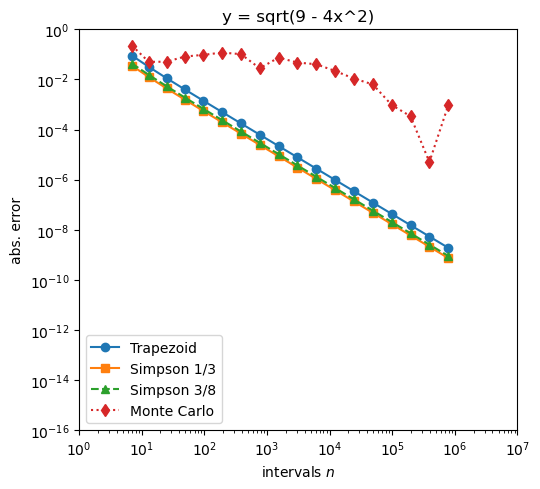

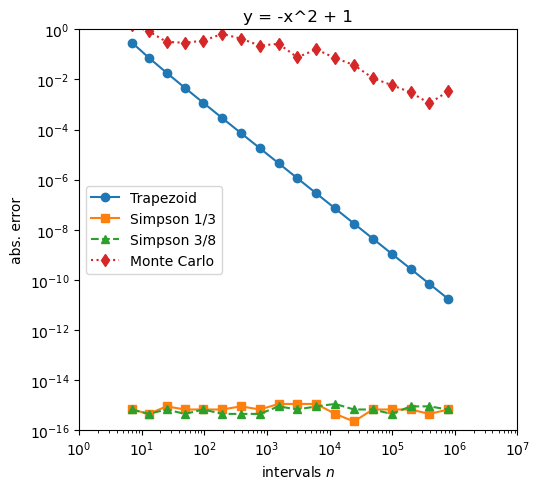

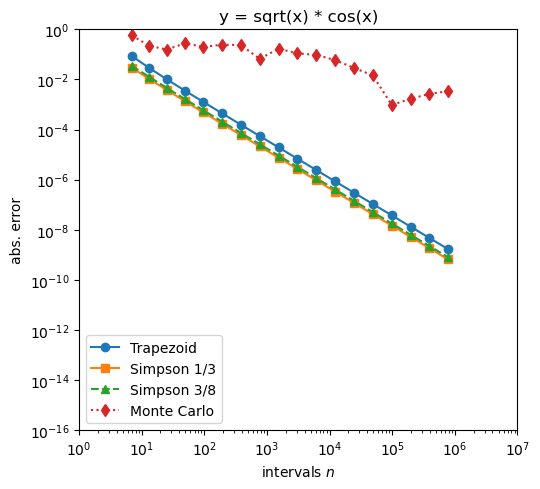

In [24]:
ns = [6*2**k + 1 for k in range(18)]   # 7, 13, 25, ..., 786433 points (n - 1 divisible by 2 and 3)

for i, (f, a, b, name) in enumerate(tests, start=1):
    exact, quad_err = quad(f, a, b)

    # absolute error of each method at every n
    err_trap = []
    err_s13 = []
    err_s38 = []
    err_mc = []
    for n in ns:
        err_trap.append(abs(trapezoid(f, a, b, n)[0] - exact))
        err_s13.append(abs(simpson13(f, a, b, n)[0] - exact))
        err_s38.append(abs(simpson38(f, a, b, n)[0] - exact))
        err_mc.append(abs(montecarlo(f, a, b, n)[0] - exact))

    # log-log axes so a power-law error shows up as a straight line
    plt.figure(figsize=(5.5, 5))
    plt.loglog(ns, err_trap, "o-", label="Trapezoid")
    plt.loglog(ns, err_s13, "s-", label="Simpson 1/3")
    plt.loglog(ns, err_s38, "^--", label="Simpson 3/8")
    plt.loglog(ns, err_mc, "d:", label="Monte Carlo")
    plt.xlim(1e0, 1e7)
    plt.ylim(1e-16, 1e0)
    plt.xlabel("intervals $n$")
    plt.ylabel("abs. error")
    plt.title(name)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"11-error-{i}.png")
    plt.show()

In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

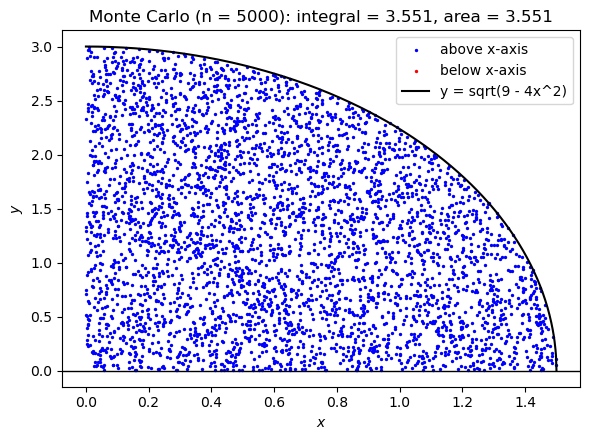

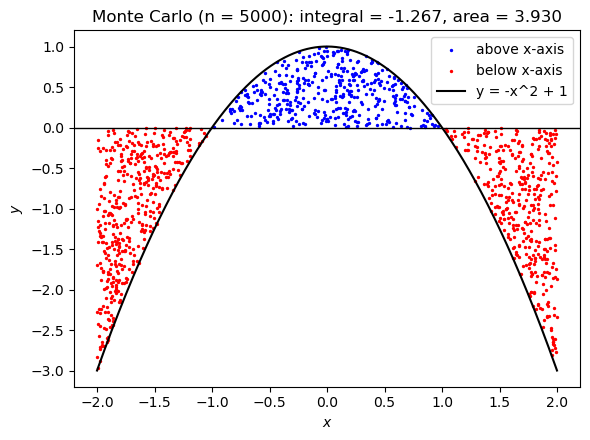

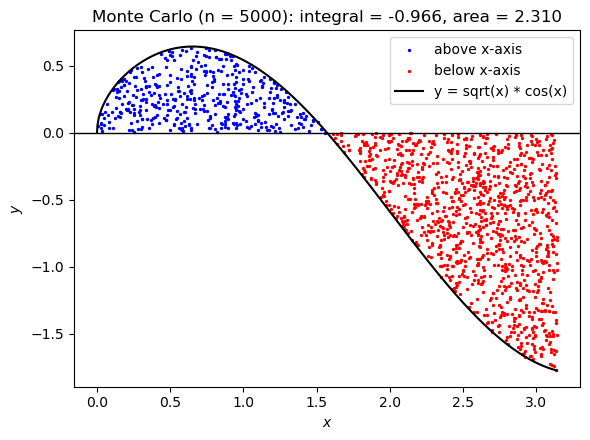

In [25]:
np.random.seed(0)
n_points = 5000    # number of random points for the plot

for i, (f, a, b, name) in enumerate(tests, start=1):
    
    # box that contains the curve and the x-axis
    xcurve = np.linspace(a, b, 1000)
    ycurve = f(xcurve)
    ymin = min(0, ycurve.min())
    ymax = max(0, ycurve.max())
    box_area = (b - a)*(ymax - ymin)

    # random points inside the box
    xs = np.random.uniform(a, b, n_points)
    ys = np.random.uniform(ymin, ymax, n_points)
    fs = f(xs)

    # points between the curve and the x-axis
    above = (ys >= 0) & (ys <= fs)    # blue: above the x-axis
    below = (ys < 0) & (ys >= fs)     # red: below the x-axis

    # region area = box_area * (points in region)/(total points)
    # signed integral: blue minus red; total area: blue plus red
    integral = box_area*(np.sum(above) - np.sum(below))/n_points
    area = box_area*(np.sum(above) + np.sum(below))/n_points

    plt.figure(figsize=(6, 4.5))
    plt.scatter(xs[above], ys[above], s=2, color="blue", label="above x-axis")
    plt.scatter(xs[below], ys[below], s=2, color="red", label="below x-axis")
    plt.plot(xcurve, ycurve, color="black", label=name)
    plt.axhline(0, color="black", linewidth=1.0)
    plt.xlabel("$x$")
    plt.ylabel("$y$")
    plt.title(f"Monte Carlo (n = {n_points}): integral = {integral:.3f}, area = {area:.3f}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"11-mc-{i}.png", dpi=150)
    plt.show()

### Problem code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---
* This code compares four integration methods (trapezoid, Simpson 1/3, Simpson 3/8, and Monte Carlo) by computing the integrals of three test functions and checking them against SciPy's `quad`. It uses integration functions based on the codes from Gezerlis' *Numerical Methods in Physics with Python*, with an added second return value for the total area found by integrating $|f|$, and loops each method over an increasing number of points to plot its absolute error on log-log axes. For the Monte Carlo visualization, it draws random points inside a box enclosing the curve and the x-axis, then uses boolean masks to keep only the points between them, coloring them blue above the axis and red below, so the signed integral and total area come directly from counting the points.